# Finding VFE Minima with Coordinate Search

Using the coordinate search algorithm to iteratively find VFE minima.

==========================================================================

* **Notebook dependencies**:
    * ...

* **Content**: Jupyter notebook accompanying Chapter 4 of the textbook "Fundamentals of Active Inference". Example 4.1.

* **Author**: Fraser Paterson (fpaterson117@gmail.com)

* **Version**: 0.1

In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import os
import sys

from scipy.stats import norm, uniform
from scipy.integrate import quad
from types import SimpleNamespace

module_path = os.path.abspath(os.path.join(os.pardir, os.pardir))
if module_path not in sys.path:
    sys.path.append(module_path)

from src.utils import create_environment

# mpl.style.use("seaborn-deep")
mpl.style.use("seaborn-v0_8-deep")

As before, we need to set up the environment and the agent. The environment (generative process) is defined as

$$
    \mathscr{E} \triangleq 
    \begin{cases}
        y = g_{\mathscr{E}}({x^*}; \theta^*) + \omega_y^*    & \text{Outcome generation} \\
        g_{\mathscr{E}}({x^*}; \theta^*) = \beta_0^* + \beta_1^* x^* & \text{Linear generating function} \\
        \omega_y^* \sim \mathcal{N}(\mu = 0, \sigma^2 = 1) & \text{Gaussian Observation Noise} \\
        \theta^* = \left \{\beta_0^* = 3, \beta_1^* = 2 \right \} & \text{Observation Parameters}
    \end{cases}
$$

and the agent (generative model) is defined as

$$
    \mathcal{M} \triangleq 
    \begin{cases}
        p_{\mu_y, \sigma^2_y}(y | x) = \mathcal{N}(y; g_{\mathcal{M}}, \sigma^2_y) & \text{Likelihood} \\
        p_{m_x, s^2_x}(x) = \mathcal{N}(x; m_x, s^2_x) & \text{Prior on x} \\
        g_{\mathcal{M}}(x; \theta) = \beta_0^* + \beta_1^* x^* & \text{Generating Function} \\
        \theta = \left \{\beta_0^* = 3, \beta_1^* = 2 \right \}  & \text{Linear parameters} \\
        \phi = \left \{\sigma^2_y = 0.25, s^2_x = 0.25, m_x = 4 \right \}  & \text{Other parameters}
    \end{cases}
$$

We will call upon the environment construct that is included in this package to generate the data. 

In [2]:
class StaticEnvironment:
    def __init__(self, params: dict) -> None:
        self.params = SimpleNamespace(**params)
        
    def _noise(self):
        return np.random.normal(loc=0, scale=self.params.y_star_std)
    
    def generating_function(self, x_star: float) -> float:
        return self.params.beta_1_star * x_star + self.params.beta_0_star
    
    def generate(self, x_star: float) -> float:
        return self.generating_function(x_star) + self._noise()
    
# Environment parameters
env_params = {
    "beta_0_star" : 3,    # Linear parameter intercept
    "beta_1_star" : 2,    # Linear parameter slope
    "y_star_std"  : 1.0   # Standard deviation of sensory data
}

# Initialize the environment and support of x
env       = StaticEnvironment(env_params)
x_range   = np.linspace(start=0.01, stop=7, num=500)

# Generate data
y = np.zeros(x_range.shape[0])

for idx, x in enumerate(x_range):
    y[idx] = env.generate(x)

<Figure size 640x480 with 0 Axes>

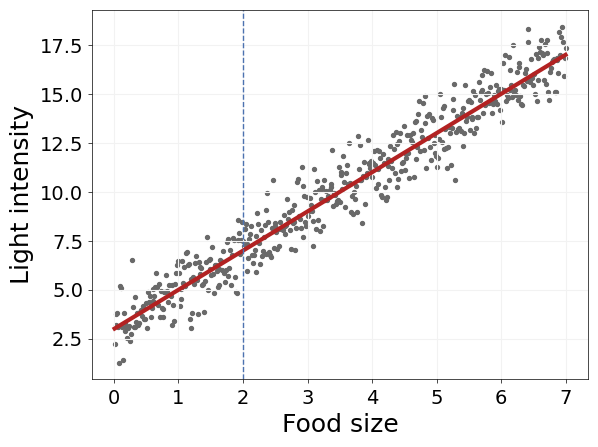

In [3]:
fig = plt.figure()
fig, ax = plt.subplots(1,1, facecolor=(1,1,1))

# Linear generating function
ax.plot(x_range, env.generating_function(x_range),
        c="#B22222", linewidth=3)

# Noisy samples
ax.scatter(x_range,y,
        c="#696969", s=8)

ax.axvline(x=2, linestyle="dashed", linewidth=1)

# Axis labels and styling
ax.set_xlabel("Food size", fontsize=18)
ax.set_ylabel("Light intensity", fontsize=18)
ax.axes.grid(which="major", axis="both", c="#f2f2f2")
plt.setp(ax.spines.values(), color="black", linewidth=0.5)
ax.tick_params(
    labelsize=14,
    axis='both',          
    which='major',      
    bottom=True,
    left=True,
    color="black",
    width=0.5,
    length=3)

In [4]:
class StaticAgent:
    def __init__(self, params: dict) -> None:
        self.params = SimpleNamespace(**params)

        self.likelihood = None
        self.prior = None

        self.variational_model_mu = self.params.mu_x
        self.variational_model_std = self.params.std_x

    def variational_model(self, x: float): # defined for a specific x
        return norm.pdf(
            x, 
            loc = self.variational_model_mu, 
            scale = self.variational_model_std
        )

    def gm(self, x: float): # defined for a specific x
        return self.params.beta_1 * x + self.params.beta_0

    def generative_model(self, y: float, x: float): # defined for specific x and y
        self.likelihood = norm.pdf(y, loc = self.gm(x), scale = self.params.std_y)
        self.prior = norm.pdf(x, loc = self.params.mu_x, scale = self.params.std_x)
        return self.likelihood * self.prior

    def compute_VFE(self, y: float): # compute the VFE of q(x), given observation: y
        
        # Define the VFE integrand
        def integrand(x):
            q_x = self.variational_model(x)
            p_x_y = self.generative_model(y, x)

            return q_x * np.log((q_x / p_x_y))

        # Perform numerical integration over x with quad from scipy.integrate
        VFE, _ = quad(integrand, self.params.x_range[0], self.params.x_range[-1], epsabs=1e-8)
        
        return VFE

    def infer_state(self, y: float, step_size: float = 0.01, tolerance: float = 1e-2):
        """
        infer_state now performs coordinate search to minimize VFE by updating the parameters
        of the variational distribution q(x) - see the main text in Example 4.1.

        Args:
            y (float): Observation: light intensity.
            step_size (float): Step size (kappa) for parameter updates.
            tolerance (float): Convergence tolerance.

        Returns:
            dict: Optimized variational parameters with history {'mu': float, 'std': float, 'history': list}.
        """
        
        current_vfe = self.compute_VFE(y)
        history = [] # store tuples of (mu, std, VFE) for later use
        iters = 0

        # iterate until stopping condition
        while True:
            
            # Store current variational parameters and current VFE
            history.append({
                "mu": self.variational_model_mu,
                "std": self.variational_model_std,
                "VFE": current_vfe
            })

            # Generate candidate updates by moving in the 8 cardinal directions by an ammount of "step_size"
            candidates = [
                (self.variational_model_mu + step_size, self.variational_model_std),  # Mu + step_size
                (self.variational_model_mu - step_size, self.variational_model_std),  # Mu - step_size
                (self.variational_model_mu, self.variational_model_std + step_size),  # Std + step_size
                (self.variational_model_mu, self.variational_model_std - step_size),  # Std - step_size
                (self.variational_model_mu + step_size, self.variational_model_std + step_size),  # Mu + step_size, Std + step_size
                (self.variational_model_mu - step_size, self.variational_model_std - step_size),  # Mu - step_size, Std - step_size
                (self.variational_model_mu + step_size, self.variational_model_std - step_size),  # Mu + step_size, Std - step_size
                (self.variational_model_mu - step_size, self.variational_model_std + step_size),  # Mu - step_size, Std + step_size
            ]

            # Evaluate the VFE for each candidate solution
            vfes = []
            for mu, std in candidates:
                if std > 0:  # standard deviation must be positive
                    self.variational_model_mu = mu
                    self.variational_model_std = std
                    vfe = self.compute_VFE(y)
                    vfes.append((mu, std, vfe))

            # Select the candidate with the lowest VFE
            best_candidate = min(vfes, key = lambda x: x[2]) # select the tuple in vfes with the least VFE
            best_mu, best_std, best_vfe = best_candidate

            print(f"\ncurrent_vfe: {current_vfe}")
            print(f"best_vfe: {best_vfe}")
            print(f"abs(current_vfe - best_vfe): {abs(current_vfe - best_vfe)}")
            print(f"best_mu: {best_mu}")
            print(f"best_std: {best_std}")
            print(f"iteration: {iters}\n")

            # Check for convergence
            if abs(current_vfe - best_vfe) < tolerance:
                print(f"converged in {iters} iterations")
                break

            # Update the variational distribution's parameters
            self.variational_model_mu = best_mu
            self.variational_model_std = best_std
            current_vfe = best_vfe

            iters += 1

        return {"mu": self.variational_model_mu, "std": self.variational_model_std, "history": history}

Now assuming that $x^*=2$, we can generate a deterministic observation at $y=7$ and perform Bayesian inference.

In [5]:
# Agent parameters
agent_params = {
    "beta_0" : 3,    # Linear parameter intercept
    "beta_1" : 2,    # Linear parameter slope
    "std_y"  : 0.25, # Likelihood standard deviation
    "mu_x"   : 4,    # Prior mean
    "std_x"  : 0.25, # Prior standard deviation
    "x_range": np.linspace(start=0.01, stop=5, num=500)
}

In [6]:
# Initialize environment and agent
env       = StaticEnvironment(env_params)
agent     = StaticAgent(agent_params)

# Set true state and generate sensory data
x_star    = 2
y         = 7

In [7]:
prior_variational_pdf = [agent.variational_model(x) for x in agent.params.x_range]
generative_pdf = [agent.generative_model(y, x) for x in agent.params.x_range]

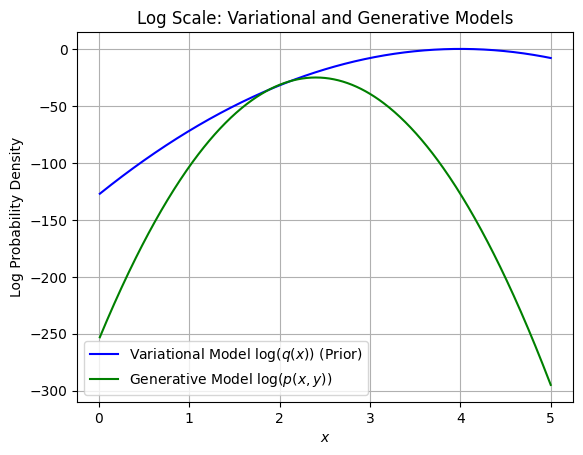

In [8]:
log_prior_variational_pdf = np.log(prior_variational_pdf)
log_generative_pdf = np.log(generative_pdf)

plt.plot(agent.params.x_range, log_prior_variational_pdf, label=r"Variational Model $\log(q(x))$ (Prior)", color="blue")
plt.plot(agent.params.x_range, log_generative_pdf, label=r"Generative Model $\log(p(x, y))$", color="green")
plt.title("Log Scale: Variational and Generative Models")
plt.xlabel(r"$x$")
plt.ylabel("Log Probability Density")
plt.legend()
plt.grid(True)

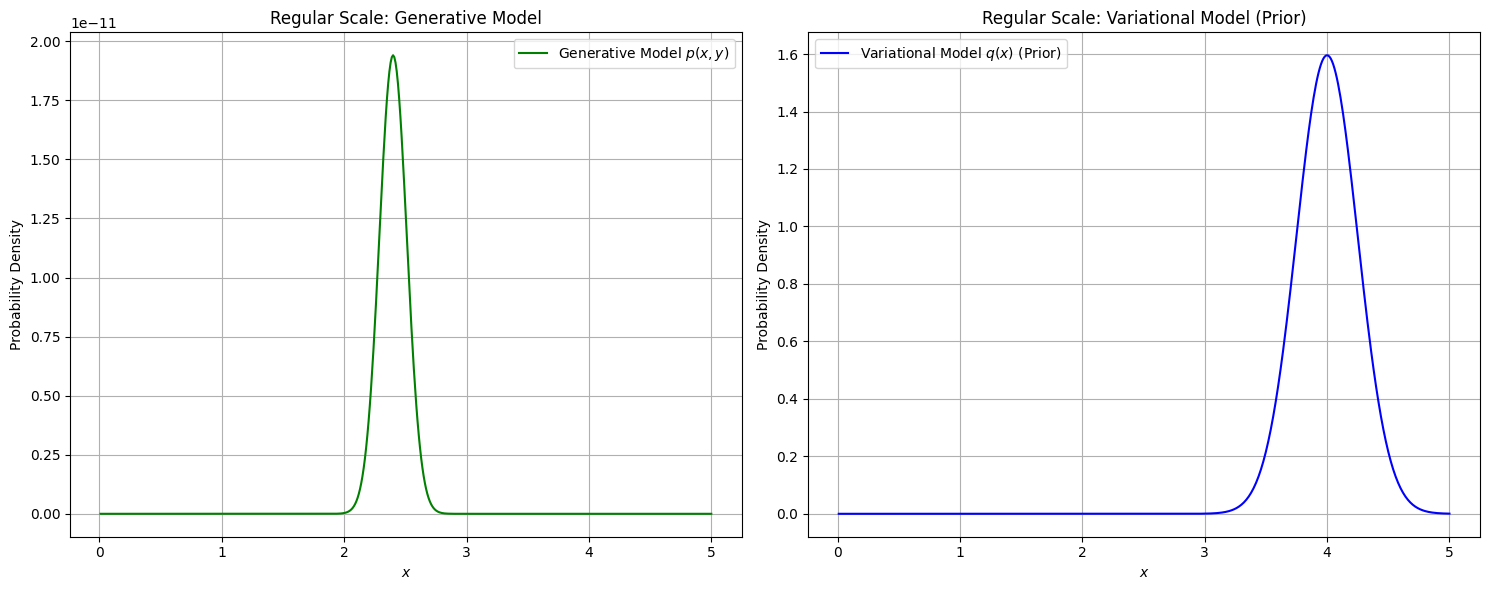

In [10]:
# Create the subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Generative Model 
axes[0].plot(agent.params.x_range, generative_pdf, label=r"Generative Model $p(x, y)$", color="green")
axes[0].set_title("Regular Scale: Generative Model")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel("Probability Density")
axes[0].legend()
axes[0].grid(True)

# Right plot: Variational Model 
axes[1].plot(agent.params.x_range, prior_variational_pdf, label=r"Variational Model $q(x)$ (Prior)", color="blue")
axes[1].set_title("Regular Scale: Variational Model (Prior)")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel("Probability Density")
axes[1].legend()
axes[1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

In [10]:
# Perception: Agent infers belief over hidden state using sensory data
results = agent.infer_state(y)


current_vfe: 129.52318850335539
best_vfe: 128.097648846518
abs(current_vfe - best_vfe): 1.4255396568373726
best_mu: 3.99
best_std: 0.24
iteration: 0


current_vfe: 128.097648846518
best_vfe: 126.68666682545907
abs(current_vfe - best_vfe): 1.4109820210589419
best_mu: 3.9800000000000004
best_std: 0.22999999999999998
iteration: 1


current_vfe: 126.68666682545907
best_vfe: 125.29206109493094
abs(current_vfe - best_vfe): 1.3946057305281272
best_mu: 3.9700000000000006
best_std: 0.21999999999999997
iteration: 2


current_vfe: 125.29206109493094
best_vfe: 123.91489095993465
abs(current_vfe - best_vfe): 1.377170134996291
best_mu: 3.960000000000001
best_std: 0.20999999999999996
iteration: 3


current_vfe: 123.91489095993465
best_vfe: 122.55576578027976
abs(current_vfe - best_vfe): 1.359125179654896
best_mu: 3.950000000000001
best_std: 0.19999999999999996
iteration: 4


current_vfe: 122.55576578027976
best_vfe: 121.21507755699231
abs(current_vfe - best_vfe): 1.3406882232874437
best_mu: 3.940000

In [15]:
posterior_variational_pdf = norm.pdf(
    agent.params.x_range, 
    loc = results["mu"], 
    scale = results["std"]
)

log_posterior_variational_pdf = np.log(posterior_variational_pdf)

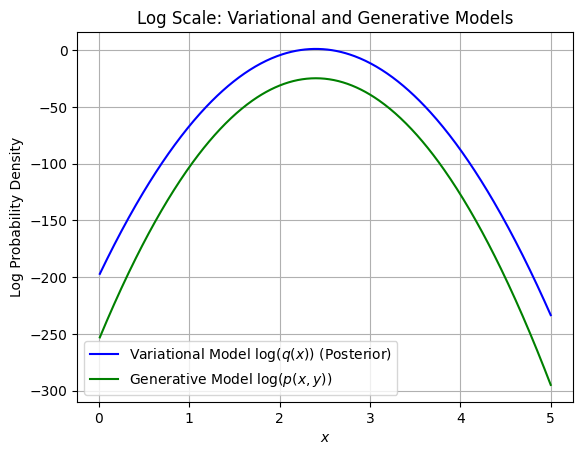

In [19]:
plt.plot(agent.params.x_range, log_posterior_variational_pdf, label=r"Variational Model $\log(q(x))$ (Posterior)", color="blue")
plt.plot(agent.params.x_range, log_generative_pdf, label=r"Generative Model $\log(p(x, y))$", color="green")
plt.title("Log Scale: Variational and Generative Models")
plt.xlabel(r"$x$")
plt.ylabel("Log Probability Density")
plt.legend()
plt.grid(True)

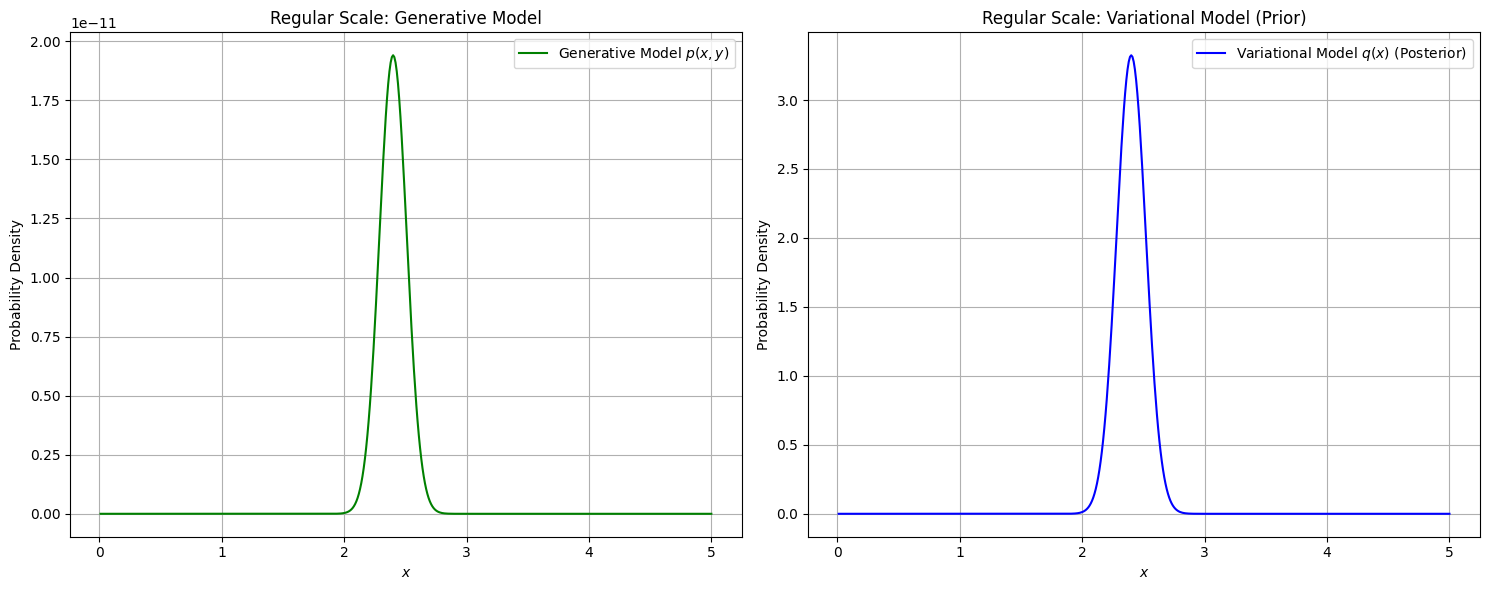

In [20]:
# Create the subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Generative Model 
axes[0].plot(agent.params.x_range, generative_pdf, label=r"Generative Model $p(x, y)$", color="green")
axes[0].set_title("Regular Scale: Generative Model")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel("Probability Density")
axes[0].legend()
axes[0].grid(True)

# Right plot: Variational Model 
axes[1].plot(agent.params.x_range, posterior_variational_pdf, label=r"Variational Model $q(x)$ (Posterior)", color="blue")
axes[1].set_title("Regular Scale: Variational Model (Posterior)")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel("Probability Density")
axes[1].legend()
axes[1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

In [14]:
print("Optimized Mean:", results["mu"])
print("Optimized Std:", results["std"])

Optimized Mean: 2.400000000000034
Optimized Std: 0.1199999999999999


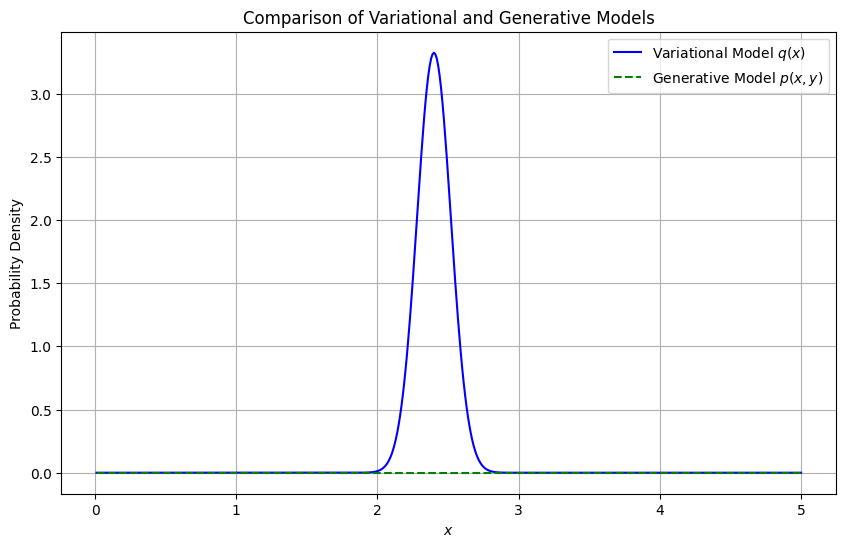

In [21]:
# Compute the variational model PDF
variational_pdf = norm.pdf(
    agent.params.x_range, 
    loc = results["mu"], 
    scale = results["std"]
)

# Compute the generative model PDF
generative_pdf = [agent.generative_model(y, x) for x in agent.params.x_range]

# Plot the PDFs
plt.figure(figsize=(10, 6))

plt.plot(agent.params.x_range, variational_pdf, label="Variational Model $q(x)$", color="blue")
plt.plot(agent.params.x_range, generative_pdf, label="Generative Model $p(x, y)$", color="green", linestyle="--")

plt.title("Comparison of Variational and Generative Models")
plt.xlabel("$x$")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True)